# 01. Data exxploration і розбиття train/val/test

### 1) Імпорти, шляхи, seed

Підключаємо бібліотеки і шляхи (знімки для навчання, результати).
`SEED = 42`.

In [ ]:
from pathlib import Path
import re
import random

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold

DATA_DIR = Path("../data/chest_xray") 
RESULTS_DIR = Path("../results")
RESULTS_DIR.mkdir(exist_ok=True)

SEED = 42
random.seed(SEED)

### 2) Каталог знімків

Формуємо таблицю всіх знімків для папок NORMAL/PNEUMONIA в train, val, test.

In [2]:
rows = []
for split in ["train", "val", "test"]:
    for label in ["NORMAL", "PNEUMONIA"]:
        for p in (DATA_DIR / split / label).glob("*"):
            if p.suffix.lower() in {".jpeg", ".jpg", ".png"}:
                rows.append({"split": split, "label": label, "filename": p.name})

df = pd.DataFrame(rows)
print("Всього знімків:", len(df))
df.groupby(["split", "label"]).size().unstack()

Всього знімків: 5856


label,NORMAL,PNEUMONIA
split,,
test,234,390
train,1341,3875
val,8,8


За результатами таблиці знімки розподілені нерівномірно, тому нижче перерозподілимо дані.

### 3) Графік розподілу класів

З таблиці будуємо діаграму, щоб показати нерівномірний розподіл.

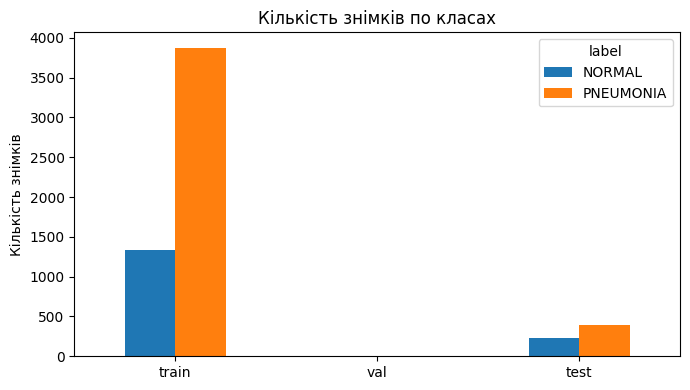

Частка пневмонії в train: 74.3%


In [3]:
counts = df.groupby(["split", "label"]).size().unstack().loc[["train", "val", "test"]]

counts.plot(kind="bar", figsize=(7, 4))
plt.title("Кількість знімків по класах")
plt.ylabel("Кількість знімків")
plt.xlabel("")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "class_balance.png", dpi=150)
plt.show()

train_part = counts.loc["train"]
print(f"Частка пневмонії в train: {train_part['PNEUMONIA'] / train_part.sum():.1%}")

В результаті бачимо, що знімків з пневмонією набагато більше, ніж без. Тому надалі будемо звертати увагу на recall (скільки знайшли хворих) і specificity (скільки здорових назвали здоровими).

### 4) Приклади знімків

Розглянемо випадкові знімки з пневмонією і здорових дітей.

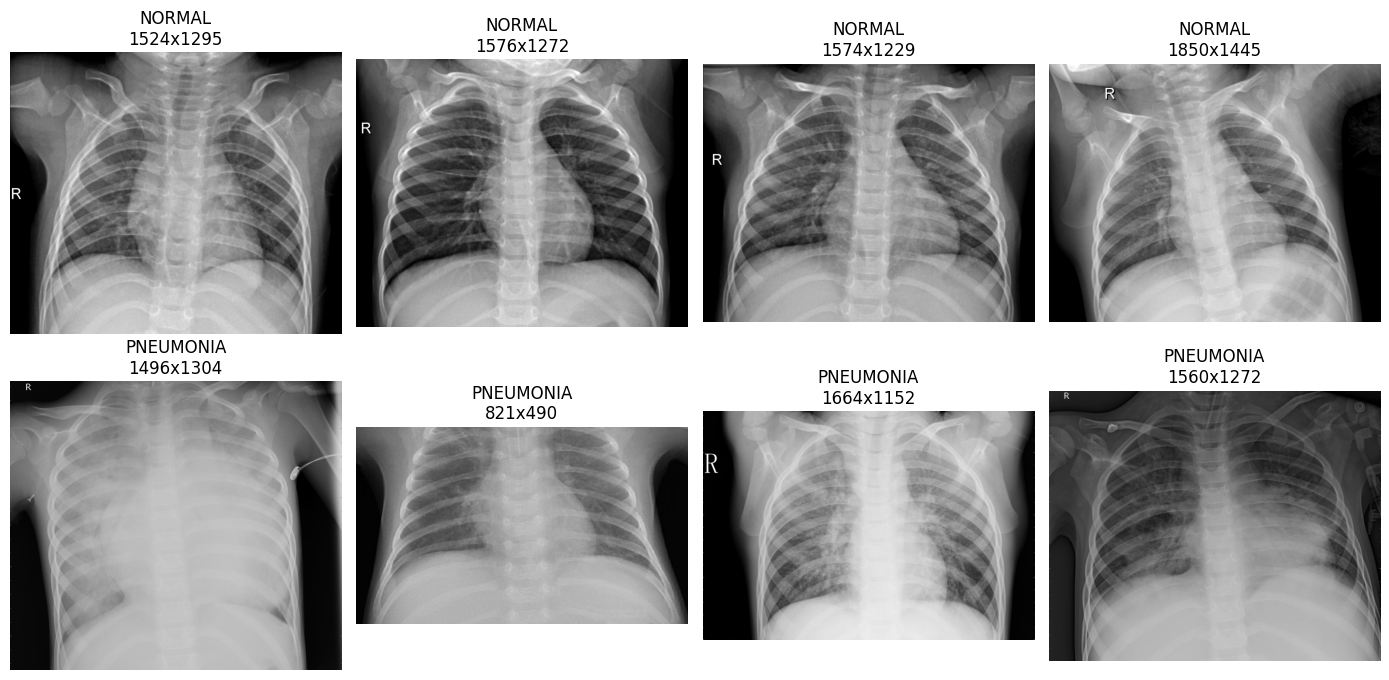

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for row, label in enumerate(["NORMAL", "PNEUMONIA"]):
    sample = df[(df["split"] == "train") & (df["label"] == label)].sample(4, random_state=SEED)
    for ax, (_, r) in zip(axes[row], sample.iterrows()):
        img = Image.open(DATA_DIR / r["split"] / r["label"] / r["filename"])
        ax.imshow(img, cmap="gray")
        ax.set_title(f"{label}\n{img.size[0]}x{img.size[1]}")
        ax.axis("off")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "examples.png", dpi=150)
plt.show()

Якщо вручну звіряти знімки, можна помітити, що здорові легені темніші, чітко видно ребра. Але деякі неоднозначні, також є літера R, розтташована скрізь по-різному. Це ускладнює навчання.

### 5) Розмір і формат знімків

Нам потрібно привести всі зображення до одного розміру і формату. Для цього візьмемо 300 випадкових, запишемо їх ширину, висоту та кольори (чорно-білі чи RGB), щоб знайти оптимальні значення.

In [5]:
sample = df.sample(300, random_state=SEED)
info = []
for _, r in sample.iterrows():
    img = Image.open(DATA_DIR / r["split"] / r["label"] / r["filename"])
    info.append({"width": img.size[0], "height": img.size[1], "mode": img.mode})

info_df = pd.DataFrame(info)
print(info_df[["width", "height"]].describe())
print(info_df["mode"].value_counts())

             width       height
count   300.000000   300.000000
mean   1300.336667   950.363333
std     342.171606   356.168628
min     467.000000   191.000000
25%    1024.000000   683.750000
50%    1284.000000   888.000000
75%    1539.500000  1152.000000
max    2302.000000  2067.000000
mode
L      282
RGB     18
Name: count, dtype: int64


### Результат:

Середній розмір: 1300 * 950. Але через широкий діапазон медіана 1284 * 888.
Колір: більшість знімків чорно-білі, але є й кольорові, треба вирівняти кількість каналів.

Надалі кожен знімок переводимо в чорно-білий і зменшуємо до квадрата 128 * 128 (ML та CNN) або 224 * 224 (transfer learning). Стиснення до квадрата трохи спотворить пропорції.

### 6) Розшифровка назв файлів

Друкуємо перші 5 назв файлів для кожного класу. Тому що у назві може бути ідентифікатор пацієнта.

In [6]:
for label in ["NORMAL", "PNEUMONIA"]:
    print(label, df[df["label"] == label]["filename"].head(5).tolist())

NORMAL ['IM-0115-0001.jpeg', 'IM-0117-0001.jpeg', 'IM-0119-0001.jpeg', 'IM-0122-0001.jpeg', 'IM-0125-0001.jpeg']
PNEUMONIA ['person1000_bacteria_2931.jpeg', 'person1000_virus_1681.jpeg', 'person1001_bacteria_2932.jpeg', 'person1002_bacteria_2933.jpeg', 'person1003_bacteria_2934.jpeg']


Видно, що знімки з пневмонією мають в назві bacteria або virus (тип пневмонії), а також починаються з person + номер людини.
Знімки здорових людей також мають певний номер у назві, що також може бути номером пацієнта.

Тобто за назвою можна визначити знімки певного пацієнта.

### 7) Група знімків пацієнта за назвою

Шукаємо ідентифіактор групи за допомогою шаблону пошуку в тексті. В наступних кроках ми будемо ділити дані за групами, тому потрібно перевірити чи справді щось знайдемо за шаблоном.

In [7]:
def get_group(filename, label):
    name = filename.lower()
    if label == "PNEUMONIA":
        m = re.match(r"(person\d+_[a-z]+)", name)
    else:
        m = re.search(r"im-(\d+)", name)
    return f"{label}_{m.group(1)}" if m else f"{label}_{name}"

df["group"] = [get_group(f, l) for f, l in zip(df["filename"], df["label"])]

print("Унікальних груп (пацієнтів) по класах:")
print(df.groupby("label")["group"].nunique())
print("\nЗнімків на групу в середньому:")
print(df.groupby("label").size() / df.groupby("label")["group"].nunique())

Унікальних груп (пацієнтів) по класах:
label
NORMAL       1116
PNEUMONIA    2653
Name: group, dtype: int64

Знімків на групу в середньому:
label
NORMAL       1.418459
PNEUMONIA    1.610629
dtype: float64


Бачимо, що на групу випадає 1.4 (NORMAL) і 1.6 (PNEUMONIA), отже в датасеті є пацієнти з кількома знімками.

### 8) Нове розбиття train/val

Об'єднуємо train і val в один пул (test залишаємо без змін). Ділимо пул на 5 частин з двома умовами: усі знімки одного пацієнта потрапляють в одну частину і пропорція класів зберігається.
Перша частина стає val, решта train. В кінці перевіряємо чи не потрапили знімки одного пацієнта і в train, і у val.

In [ ]:
pool = df[df["split"].isin(["train", "val"])].reset_index(drop=True)
test = df[df["split"] == "test"].copy()  

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, val_idx = next(sgkf.split(pool, pool["label"], groups=pool["group"]))

pool["new_split"] = "train"
pool.loc[val_idx, "new_split"] = "val"
test["new_split"] = "test"

final = pd.concat([pool, test], ignore_index=True)

print(final.groupby(["new_split", "label"]).size().unstack())

overlap = set(pool.loc[train_idx, "group"]) & set(pool.loc[val_idx, "group"])
print("\nПацієнтів, що є і в train, і в val:", len(overlap))

label      NORMAL  PNEUMONIA
new_split                   
test          234        390
train        1079       3081
val           270        802

Пацієнтів, що є і в train, і в val: 0


Результат вийшов, який і очікувався.

Примітка: test ми не чіпали, тому не знаємо чи є там перетини знімків пацієнтів.

### 9) Зберігаємо розбиття

Всі моделі будуть навчатися на однакових модифікованих даних.

In [10]:
final.to_csv(RESULTS_DIR / "splits.csv", index=False)
final.head()

,split,label,filename,group,new_split
0,train,NORMAL,IM-0115-0001.jpeg,NORMAL_0115,train
1,train,NORMAL,IM-0117-0001.jpeg,NORMAL_0117,train
2,train,NORMAL,IM-0119-0001.jpeg,NORMAL_0119,train
3,train,NORMAL,IM-0122-0001.jpeg,NORMAL_0122,train
4,train,NORMAL,IM-0125-0001.jpeg,NORMAL_0125,train


## Підсумок

**Інформація про дані**
- 5 856 знімків, 2 класи. Пневмонії 74,3% у train: дисбаланс і різні пропорції.
- Знімки різного розміру, деякі з них кольорові: потрібна однакова передобробка.
- Від одного пацієнта може бути кілька знімків, тому ділимо дані за групами.

**Що ми зробили**
- Нове розбиття: train 4 160 / val 1 072 / test 624, без перетину пацієнтів між train і val.